# StyleVector Extension — Multi-Component Style Vectors with Norm-Preserving Steering
### (LaMP_4 News Headline · LaMP_5 Scholarly Title · LaMP_7 Tweet Paraphrasing)

This is the **end-term notebook**. It re-uses the midterm pipeline (same data loading,
same LLaMA-2-7B-chat 4-bit model, same prompts, same metrics, same hardcoded layer / alpha)
and adds the two extensions from the project proposal.

## The method

For each user we collect contrastive differences at layer $\ell$:
$\Delta_i = a^\ell_{p,i} - a^\ell_{n,i}$ (authentic minus style-agnostic last-token activation).

| | Original StyleVector | **Ours** |
|---|---|---|
| Style representation | one mean-difference vector $s_u=\frac1{|P_u|}\sum_i\Delta_i$ | **top-$k$ principal components** $\{v_1..v_k\}$ of $\{\Delta_i\}\cup\{-\Delta_i\}$ (eigenvectors of $\sum_i \Delta_i\Delta_i^\top+(-\Delta_i)(-\Delta_i)^\top$, i.e. Eq. 10 for $k>1$) |
| Steering | $h' = h + \alpha s_u$ | $h' = \lVert h\rVert\cdot\dfrac{h+p}{\lVert h+p\rVert}$ with $p=\alpha\lVert\bar\Delta\rVert\sum_j w_j v_j$, $w_j\propto\sqrt{\lambda_j}$ |

### Design decisions (so the comparison is fair and reproducible)
1. **Sign alignment.** Eigenvectors of the symmetrised set have an arbitrary sign (that is the point of adding $-\Delta_i$).
   For steering we need a direction, so every $v_j$ is flipped so that $v_j\cdot\bar\Delta\ge 0$.
2. **Same units as the baseline.** The baseline perturbation is $\alpha\bar\Delta$ (norm $\alpha\lVert\bar\Delta\rVert$).
   We normalise the weights so $\sum_j w_j^2=1$; since the $v_j$ are orthonormal, $\lVert p\rVert=\alpha\lVert\bar\Delta\rVert$ **for every $k$**.
   Hence the *same* `alpha` from `BEST_CONFIG` is directly comparable across all methods, and changing $k$ changes only the
   *direction* of the perturbation, never its size.
3. **Norm preservation** rescales the steered activation back to $\lVert h\rVert$ at each intervened token, so the perturbation can
   only *rotate* the activation, never inflate it.
4. **Caching.** The expensive part (generating $\hat y_i$ and the $2|P_u|$ forward passes) is done **once per user for several layers**
   and stored on disk; every steering variant, sweep and ablation re-uses it. The whole notebook is resumable.

### Experiments
| Tag | What | Users |
|---|---|---|
| `main` | Full 2×2 ablation (single vs. multi-component × additive vs. norm-preserving) and $k\in\{1,3,5\}$, at the midterm `alpha` | all eval users |
| `strength` | Steering-strength sweep (tests the *"norm preservation tolerates larger $\alpha$"* hypothesis) | subset |
| `layer` | Steering-layer sweep | subset |

### Carried over unchanged from the midterm
LLaMA-2-7B-chat, **4-bit NF4** (hardware-driven deviation from the paper's 8-bit, RTX 3060 12 GB), greedy decoding,
history cap 15, `BEST_CONFIG` layer/alpha, the same $M_g=M$ generic-response generation.

> **Note on reporting.** All numbers produced here are raw measurements. Nothing is adjusted, offset or rescaled.
> The verdict cells at the end use paired bootstrap confidence intervals, so a result is only called an improvement if it is
> distinguishable from zero.

## Part 0 — Environment Setup

In [1]:
# Cell 0.1 — Working directory (local lab PC, no Drive/Kaggle mount needed)
import os
PROJECT_DIR = os.path.expanduser('~/stylevector_project')
os.makedirs(PROJECT_DIR, exist_ok=True)
os.chdir(PROJECT_DIR)
print("Working directory:", os.getcwd())

Working directory: /home/user/stylevector_project


In [2]:
# Cell 0.2 — Install dependencies
!pip install -q transformers accelerate bitsandbytes rouge-score nltk huggingface_hub scikit-learn scipy --upgrade


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [3]:
# Cell 0.3 — NLTK data (with fallback if blocked)
import os
os.environ["NLTK_ALLOW_PROXIED_URLOPEN"] = "1"
import nltk
try:
    nltk.pathsec.ALLOW_PROXIED_FETCH = True
except AttributeError:
    pass

NLTK_OK = True
try:
    nltk.download('wordnet', quiet=True)
    nltk.download('punkt', quiet=True)
    nltk.download('punkt_tab', quiet=True)
    nltk.download('omw-1.4', quiet=True)
    from nltk import word_tokenize
    from nltk.translate.meteor_score import meteor_score
    _ = word_tokenize("test sentence")
    _ = meteor_score([["test", "sentence"]], ["test", "sentence"])
    print("NLTK data OK -- using real METEOR + real tokenizer.")
except Exception as e:
    NLTK_OK = False
    print(f"NLTK data unavailable ({e}). Falling back to unigram-F1 METEOR proxy.")

/home/user/stylevector_env/lib/python3.12/site-packages/nltk/downloader.py:1076: UserWarning: NLTK will not authorize the non-private download directory '/home/user/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force):


NLTK data OK -- using real METEOR + real tokenizer.


In [4]:
# Cell 0.4 — Imports
import json, time, re, random
from pathlib import Path

import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import logging
logging.getLogger("transformers").setLevel(logging.ERROR)

plt.rcParams["figure.dpi"] = 110
RNG_SEED = 42
print("Imports OK. CUDA available:", torch.cuda.is_available())
from collections import OrderedDict

Imports OK. CUDA available: True


/home/user/stylevector_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Part 1 — Download & Load LaMP (dev split)

In [5]:
%%writefile download_lamp.sh
#!/usr/bin/env bash
set -euo pipefail
OUT_DIR="${1:-./data/lamp}"
BASE_URL="https://ciir.cs.umass.edu/downloads/LaMP"

declare -A TASKS=(
  [LaMP_4]="News Headline Generation"
  [LaMP_5]="Scholarly Title Generation"
  [LaMP_7]="Tweet Paraphrasing"
)
SPLITS=(train dev test)
FILE_TYPES=(questions outputs)

for task in "${!TASKS[@]}"; do
  echo "== ${task}: ${TASKS[$task]} =="
  for split in "${SPLITS[@]}"; do
    mkdir -p "${OUT_DIR}/${task}/${split}"
    for ftype in "${FILE_TYPES[@]}"; do
      url="${BASE_URL}/${task}/${split}/${split}_${ftype}.json"
      out="${OUT_DIR}/${task}/${split}/${split}_${ftype}.json"
      if [ -f "${out}" ]; then
        echo "  [cached] ${out}"
        continue
      fi
      echo "  fetching ${url}"
      if curl -sSf --retry 3 --max-time 60 -o "${out}" "${url}"; then
        echo "    saved -> ${out}"
      else
        echo "    [skip] not publicly available: ${url}"
        rm -f "${out}"
      fi
    done
  done
done
echo "Done."

Overwriting download_lamp.sh


In [6]:
# Cell 1.2 — Run the download (idempotent, safe to re-run)
!bash download_lamp.sh ./data/lamp
!ls -la ./data/lamp/LaMP_5/dev/

== LaMP_7: Tweet Paraphrasing ==
  [cached] ./data/lamp/LaMP_7/train/train_questions.json
  [cached] ./data/lamp/LaMP_7/train/train_outputs.json
  [cached] ./data/lamp/LaMP_7/dev/dev_questions.json
  [cached] ./data/lamp/LaMP_7/dev/dev_outputs.json
  [cached] ./data/lamp/LaMP_7/test/test_questions.json
  [cached] ./data/lamp/LaMP_7/test/test_outputs.json
== LaMP_4: News Headline Generation ==
  [cached] ./data/lamp/LaMP_4/train/train_questions.json
  [cached] ./data/lamp/LaMP_4/train/train_outputs.json
  [cached] ./data/lamp/LaMP_4/dev/dev_questions.json
  [cached] ./data/lamp/LaMP_4/dev/dev_outputs.json
  [cached] ./data/lamp/LaMP_4/test/test_questions.json
  [cached] ./data/lamp/LaMP_4/test/test_outputs.json
== LaMP_5: Scholarly Title Generation ==
  [cached] ./data/lamp/LaMP_5/train/train_questions.json
  [cached] ./data/lamp/LaMP_5/train/train_outputs.json
  [cached] ./data/lamp/LaMP_5/dev/dev_questions.json
  [cached] ./data/lamp/LaMP_5/dev/dev_outputs.json
  [cached] ./data/lamp/

In [7]:
%%writefile load_lamp_data.py
import json
from pathlib import Path
from typing import Optional

TASK_PROFILE_FIELDS = {
    "LaMP_4": ("text", "title"),
    "LaMP_5": ("abstract", "title"),
    "LaMP_7": (None, "text"),
}


def load_json(path: Path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def build_gold_lookup(outputs_json: dict) -> dict:
    return {item["id"]: item["output"] for item in outputs_json["golds"]}


def make_synthetic_input(y_text: str) -> str:
    return "Write a short tweet."


def load_task_split(data_dir: Path, task: str, split: str,
                     max_users: Optional[int] = None,
                     max_history_per_user: Optional[int] = None,
                     min_history_len: int = 3):
    assert task in TASK_PROFILE_FIELDS, f"Unsupported/unmapped task: {task}"
    input_field, output_field = TASK_PROFILE_FIELDS[task]

    q_path = data_dir / task / split / f"{split}_questions.json"
    o_path = data_dir / task / split / f"{split}_outputs.json"

    questions = load_json(q_path)
    gold_lookup = {}
    if o_path.exists():
        gold_lookup = build_gold_lookup(load_json(o_path))

    for q in questions:
        if q["profile"]:
            sample = q["profile"][0]
            print(f"[{task}/{split}] sample profile item keys: {list(sample.keys())}")
            if output_field not in sample:
                raise KeyError(f"Expected output field '{output_field}' not found in {sample}")
            break

    users = {}
    for q in questions:
        user_id = q["id"]
        history = []
        for item in q["profile"]:
            y_i = item.get(output_field)
            if y_i is None:
                continue
            x_i = item.get(input_field) if input_field is not None else make_synthetic_input(y_i)
            history.append((x_i, y_i))

        if len(history) < min_history_len:
            continue
        if max_history_per_user is not None:
            history = history[:max_history_per_user]

        gold = gold_lookup.get(user_id)
        if gold is None:
            continue

        users[user_id] = {"history": history, "query_input": q["input"], "query_gold": gold}
        if max_users is not None and len(users) >= max_users:
            break

    return users

Overwriting load_lamp_data.py


In [8]:
# Cell 1.4 — Load all 3 tasks, per-task history cap, shuffled val/eval split
from load_lamp_data import load_task_split
from pathlib import Path

TASKS = ["LaMP_4", "LaMP_5", "LaMP_7"]
DATA_DIR = Path("./data/lamp")

# History cap per task (same as the midterm notebook)
MAX_HISTORY_PER_USER_BY_TASK = {
    "LaMP_4": 15,
    "LaMP_5": 15,
    "LaMP_7": 15,
}

N_VAL_USERS = 0   # alpha/layer are hardcoded from the midterm (Part 4)
N_EVAL_USERS_CAP = 300   # adjust based on your timing test in Part 4.5

val_users, eval_users = {}, {}
for task in TASKS:
    cap = MAX_HISTORY_PER_USER_BY_TASK[task]
    pool = load_task_split(
        data_dir=DATA_DIR, task=task, split="dev",
        max_users=None, max_history_per_user=cap, min_history_len=3,
    )
    all_ids = list(pool.keys())
    random.Random(RNG_SEED).shuffle(all_ids)

    eval_ids = all_ids[N_VAL_USERS:N_VAL_USERS + N_EVAL_USERS_CAP]
    eval_users[task] = {uid: pool[uid] for uid in eval_ids}

    avg_hist = np.mean([len(u["history"]) for u in eval_users[task].values()])
    print(f"{task}: pool={len(pool)}, eval={len(eval_users[task])} users, "
          f"history_cap={cap}, avg_actual_history={avg_hist:.1f}")

[LaMP_4/dev] sample profile item keys: ['text', 'title', 'id']
LaMP_4: pool=1925, eval=300 users, history_cap=15, avg_actual_history=14.1
[LaMP_5/dev] sample profile item keys: ['title', 'abstract', 'id']
LaMP_5: pool=2500, eval=300 users, history_cap=15, avg_actual_history=15.0
[LaMP_7/dev] sample profile item keys: ['text', 'id']
LaMP_7: pool=1500, eval=300 users, history_cap=15, avg_actual_history=12.5


## Part 2 — Load LLaMA-2-7B-chat (4-bit, same as midterm)

Requires a HuggingFace token with approved access to `meta-llama/Llama-2-7b-chat-hf`.

In [9]:
# Cell 2.1 — Clean up any stale GPU memory from a previous session first
import gc, torch
for var_name in ["model", "tokenizer"]:
    if var_name in dir():
        del globals()[var_name]
gc.collect()
torch.cuda.empty_cache()
if torch.cuda.is_available():
    print(f"GPU memory allocated: {torch.cuda.memory_allocated()/1e9:.2f} GB")
    print(f"GPU memory reserved:  {torch.cuda.memory_reserved()/1e9:.2f} GB")

GPU memory allocated: 0.00 GB
GPU memory reserved:  0.00 GB


In [10]:
# Cell 2.2 — Load tokenizer + model (4-bit NF4 -- see Part 0 note on why)
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

MODEL_NAME = "meta-llama/Llama-2-7b-chat-hf"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_quant_type="nf4",
)
# To match the paper's exact 8-bit setup instead (needs a GPU with more
# headroom, e.g. 16GB+), comment out the block above and use:
#   quant_config = BitsAndBytesConfig(load_in_8bit=True)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16,
    device_map="auto",
    quantization_config=quant_config,
)
model.eval()
model.generation_config.max_length = 1024  # avoid huge KV-cache pre-allocation on tight VRAM

N_LAYERS = len(model.model.layers)
HIDDEN_DIM = model.config.hidden_size
print(f"Loaded {MODEL_NAME}")
print(f"Layers: {N_LAYERS} | Hidden dim: {HIDDEN_DIM}")
print(f"GPU memory allocated: {torch.cuda.memory_allocated()/1e9:.2f} GB")

Could not reach the Hub ([Errno 111] Connection refused). Using cached commit hash for 'meta-llama/Llama-2-7b-chat-hf'.
Could not reach the Hub ([Errno 101] Network is unreachable). Using cached commit hash for 'meta-llama/Llama-2-7b-chat-hf'.
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 291/291 [00:14<00:00, 19.97it/s]

Loaded meta-llama/Llama-2-7b-chat-hf
Layers: 32 | Hidden dim: 4096
GPU memory allocated: 4.19 GB


In [11]:
# Cell 2.3 — Prompt formatting (chat template, [INST] fallback)
def build_input_ids(tokenizer, prompt, device):
    messages = [{"role": "user", "content": prompt}]
    try:
        inputs = tokenizer.apply_chat_template(
            messages, add_generation_prompt=True, return_tensors="pt", return_dict=True
        )
        return inputs["input_ids"].to(device)
    except Exception:
        formatted = f"<s>[INST] {prompt} [/INST]"
        return tokenizer(formatted, return_tensors="pt").input_ids.to(device)

_test = build_input_ids(tokenizer, "Say hello.", model.device)
print("Prompt formatting OK, input shape:", _test.shape)

Prompt formatting OK, input shape: torch.Size([1, 11])


## Part 3 — Core machinery: baseline + the extension

Cells 3.1–3.3 are the midterm pipeline (extended to capture several layers in one forward pass).
Cells 3.5–3.6 are **new**: top-$k$ PCA style components, the perturbation builder, and the norm-preserving steering hook.

In [12]:
# Cell 3.1 — Task prompts (exact wording from the paper's Appendix E)
TASK_PROMPTS = {
    "LaMP_4": lambda text: f'Generate a headline for the following article "{text}".',
    "LaMP_5": lambda text: f'Generate a title for the following abstract of a paper "{text}".',
    "LaMP_7": lambda text: f'Paraphrase the following tweet without any explanation before or after it "{text}".',
}

In [13]:
# Cell 3.2 — Generation from pre-tokenised prompt ids, optionally steered.
# perturbation=None -> plain (unsteered) generation.
# norm_preserve=False -> h' = h + p           (original StyleVector, Eq. 11 with p = alpha * s)
# norm_preserve=True  -> h' = ||h|| (h+p)/||h+p||   (our Eq. 1)
def generate_text(model, tokenizer, prompt, max_new_tokens=40, do_sample=False):
    input_ids = build_input_ids(tokenizer, prompt, model.device)
    return generate_from_ids(input_ids, max_new_tokens)

def generate_from_ids(input_ids, max_new_tokens=40, layer_idx=None,
                      perturbation=None, norm_preserve=False):
    handle = None
    if perturbation is not None:
        handle = model.model.layers[layer_idx].register_forward_hook(
            make_steering_hook(perturbation, norm_preserve))
    try:
        with torch.no_grad():
            out = model.generate(
                input_ids, max_new_tokens=max_new_tokens,
                do_sample=False, pad_token_id=tokenizer.eos_token_id,
            )
    finally:
        if handle is not None:
            handle.remove()
    gen_tokens = out[0][input_ids.shape[1]:]
    return tokenizer.decode(gen_tokens, skip_special_tokens=True).strip()

In [14]:
# Cell 3.3 — Last-token activations at SEVERAL layers in one forward pass (Eq. 5)
def get_last_token_activations(model, tokenizer, text, layer_idxs, max_len=512):
    inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=max_len).to(model.device)
    captured, handles = {}, []
    def make_hook(L):
        def hook(module, inp, output):
            hs = output[0] if isinstance(output, tuple) else output
            captured[L] = hs[:, -1, :].detach().float().cpu().squeeze(0)
        return hook
    for L in layer_idxs:
        handles.append(model.model.layers[L].register_forward_hook(make_hook(L)))
    try:
        with torch.no_grad():
            model(**inputs)
    finally:
        for h in handles:
            h.remove()
    return captured

def last_prompt_activation(input_ids, layer_idx):
    """Hidden state of the last *prompt* token at one layer (used for norm diagnostics)."""
    captured = {}
    def hook(module, inp, output):
        hs = output[0] if isinstance(output, tuple) else output
        captured["h"] = hs[:, -1, :].detach().float().cpu().squeeze(0)
    handle = model.model.layers[layer_idx].register_forward_hook(hook)
    try:
        with torch.no_grad():
            model(input_ids)
    finally:
        handle.remove()
    return captured["h"]

In [15]:
# Cell 3.4 — Contrastive deltas for several layers at once, cached on disk.
# The generic responses y_hat_i (the expensive step) are generated ONCE per user;
# every steering variant / sweep afterwards reads the cache.
def compute_user_deltas_multi(model, tokenizer, history, task, layer_idxs,
                              max_history=15, max_gen_tokens=40):
    prompt_fn = TASK_PROMPTS[task]
    per_layer = {L: [] for L in layer_idxs}
    y_hats = []
    for x_i, y_i in history[:max_history]:
        if not x_i or not y_i:
            continue
        y_hat_i = generate_text(model, tokenizer, prompt_fn(x_i), max_new_tokens=max_gen_tokens)
        a_p = get_last_token_activations(model, tokenizer, f"{x_i} {y_i}", layer_idxs)
        a_n = get_last_token_activations(model, tokenizer, f"{x_i} {y_hat_i}", layer_idxs)
        for L in layer_idxs:
            per_layer[L].append(a_p[L] - a_n[L])
        y_hats.append(y_hat_i)
    if len(y_hats) == 0:
        return None, None
    return {L: torch.stack(v) for L, v in per_layer.items()}, y_hats

def delta_cache_path(task, uid):
    return DELTA_DIR / f"{task}_{str(uid).replace('/', '_')}.pt"

def get_or_compute_deltas(task, uid, history, max_history, max_gen_tokens):
    path = delta_cache_path(task, uid)
    if path.exists():
        blob = torch.load(path, map_location="cpu")
        return {L: t.float() for L, t in blob["deltas"].items()}
    deltas, y_hats = compute_user_deltas_multi(model, tokenizer, history, task, DELTA_LAYERS,
                                               max_history=max_history, max_gen_tokens=max_gen_tokens)
    if deltas is None:
        return None
    torch.save({"deltas": {L: t.half() for L, t in deltas.items()}, "y_hat": y_hats}, path)
    return {L: t.float() for L, t in deltas.items()}

### New: style directions and steering rule
`style_components` = top-$k$ eigenvectors of $\sum_i\Delta_i\Delta_i^\top+(-\Delta_i)(-\Delta_i)^\top = 2D^\top D$ (computed via SVD of the $n\times d$ delta matrix $D$; eigenvalues $\lambda_j=2\sigma_j^2$).
Note the rank is at most $n=|P_u|$, so $k_{\text{eff}}=\min(k,n)$.

In [16]:
# Cell 3.5 — [NEW] Multi-component style directions
def style_components(deltas, k):
    """Top-k PCA components of {D_i} U {-D_i}  (paper Eq. 10, generalised from k=1).
    Returns V (k_eff, d): unit-norm, mutually orthogonal, sign-aligned with the mean difference,
            lam (k_eff,): eigenvalues of  sum_i D_i D_i^T + (-D_i)(-D_i)^T = 2 D^T D."""
    D = deltas.float()
    mean_vec = D.mean(0)
    _, S, Vh = torch.linalg.svd(D, full_matrices=False)       # rows of Vh = eigenvectors
    k_eff = min(k, Vh.shape[0])
    V, lam = Vh[:k_eff], 2.0 * S[:k_eff] ** 2
    proj = V @ mean_vec
    sign = torch.where(proj >= 0, torch.ones_like(proj), -torch.ones_like(proj))
    return V * sign[:, None], lam

def build_perturbation(deltas, method, k, alpha):
    """Returns the vector p that is added to the hidden state.
       method='mean' : p = alpha * mean(Delta)                      (original StyleVector)
       method='pca'  : p = alpha * ||mean(Delta)|| * sum_j w_j v_j   with w_j ~ sqrt(lambda_j), ||w||=1
                       -> ||p|| = alpha * ||mean(Delta)|| for every k (same scale as the baseline)"""
    mean_vec = deltas.float().mean(0)
    if method == "mean":
        return alpha * mean_vec
    V, lam = style_components(deltas, k)
    w = lam.sqrt()
    if w.norm() == 0:
        return torch.zeros_like(mean_vec)
    w = w / w.norm()
    direction = (w[:, None] * V).sum(0)          # unit norm because rows of V are orthonormal
    return alpha * mean_vec.norm() * direction

In [17]:
# Cell 3.6 — [NEW] Steering hook, additive (Eq. 11) or norm-preserving (our Eq. 1)
def make_steering_hook(perturbation, norm_preserve=False):
    perturbation = perturbation.clone().float()
    def hook(module, inp, output):
        hs = output[0] if isinstance(output, tuple) else output
        h = hs[:, -1, :].float()
        new = h + perturbation.to(hs.device)
        if norm_preserve:
            new = new * (h.norm(dim=-1, keepdim=True) / new.norm(dim=-1, keepdim=True).clamp_min(1e-6))
        hs = hs.clone()
        hs[:, -1, :] = new.to(hs.dtype)
        return (hs,) + tuple(output[1:]) if isinstance(output, tuple) else hs
    return hook

In [18]:
# Cell 3.7 — Self-test of the extension maths (no model / GPU needed, runs in a second)
import torch.nn as nn
torch.manual_seed(0)
D = torch.randn(12, 64) + 2.0 * torch.randn(1, 64)          # shared style component + noise

V, lam = style_components(D, 5)
assert torch.allclose(V @ V.T, torch.eye(5), atol=1e-4),      "components must be orthonormal"
assert (V @ D.mean(0) >= 0).all(),                            "components must be sign-aligned"
assert (lam[:-1] >= lam[1:]).all(),                           "eigenvalues must be sorted"

M = sum(torch.outer(d, d) + torch.outer(-d, -d) for d in D)   # matrix in the paper's Eq. 10 solution
ev = torch.linalg.eigvalsh(M).flip(0)[:5]
assert torch.allclose(ev, lam, rtol=1e-3),                    "SVD eigenvalues must match paper's matrix"

for k in (1, 3, 5):                                           # same perturbation size for every k
    p = build_perturbation(D, "pca", k, alpha=0.7)
    assert abs(p.norm().item() - 0.7 * D.mean(0).norm().item()) < 1e-3
assert torch.allclose(build_perturbation(D, "mean", 1, 0.7), 0.7 * D.mean(0))

class _Dummy(nn.Module):
    def forward(self, x): return (x,)
h = torch.randn(2, 5, 64) * 3
p = torch.randn(64) * 5
layer = _Dummy()
handle = layer.register_forward_hook(make_steering_hook(p, norm_preserve=True))
out = layer(h)[0]; handle.remove()
assert torch.allclose(out[:, -1].norm(dim=-1), h[:, -1].norm(dim=-1), atol=1e-4), "norm must be preserved"
assert torch.equal(out[:, :-1], h[:, :-1]),                                       "other positions untouched"
handle = layer.register_forward_hook(make_steering_hook(p, norm_preserve=False))
out = layer(h)[0]; handle.remove()
assert torch.allclose(out[:, -1], h[:, -1] + p, atol=1e-4),                       "additive hook must equal h + p"

cos = torch.nn.functional.cosine_similarity(V[0], D.mean(0), dim=0).item()
print(f"All self-tests passed.  (cos(v1, mean-diff) on synthetic data = {cos:.3f})")

All self-tests passed.  (cos(v1, mean-diff) on synthetic data = 1.000)


In [19]:
# Cell 3.6 — Evaluation metrics
from rouge_score import rouge_scorer
scorer = rouge_scorer.RougeScorer(['rougeL'], use_stemmer=True)

def _simple_tokenize(text):
    return re.findall(r"\w+|[^\w\s]", text.lower())

def _simple_meteor_proxy(pred_tokens, gold_tokens):
    if not pred_tokens or not gold_tokens:
        return 0.0
    matches = sum(1 for t in pred_tokens if t in gold_tokens)
    precision = matches / len(pred_tokens)
    recall = matches / len(gold_tokens)
    if precision + recall == 0:
        return 0.0
    return (2 * precision * recall) / (precision + recall)

if NLTK_OK:
    from nltk import word_tokenize
    from nltk.translate.meteor_score import meteor_score as _real_meteor

def score_pair(pred, gold):
    rouge_l = scorer.score(gold, pred)['rougeL'].fmeasure
    if NLTK_OK:
        meteor = _real_meteor([word_tokenize(gold)], word_tokenize(pred))
    else:
        meteor = _simple_meteor_proxy(_simple_tokenize(pred), _simple_tokenize(gold))
    return rouge_l, meteor

print("Metric functions ready. Using", "REAL METEOR" if NLTK_OK else "FALLBACK METEOR proxy")

Metric functions ready. Using REAL METEOR


## Part 4 — Configuration and experiment runner

`BEST_CONFIG` is the **same hardcoded layer/alpha as the midterm** (tuned for the original additive mean-difference method).
We deliberately do *not* re-tune it for our method in the `main` experiment, so the 2×2 ablation isolates the effect of the two
ingredients at equal perturbation size. The `strength` sweep then probes other alphas.

In [20]:
# Cell 4.1 — Generation length, hardcoded per-task layer/alpha, extension settings
MAX_GEN_TOKENS_PER_TASK = {"LaMP_4": 40, "LaMP_5": 40, "LaMP_7": 40}

BEST_CONFIG = {
    "LaMP_4": {"layer": 16, "alpha": 0.02},
    "LaMP_5": {"layer": 16, "alpha": 0.02},
    "LaMP_7": {"layer": 16, "alpha": 0.5},
}

K_LIST        = [1, 3, 5]            # PCA components tested (proposal: k in {1,3,5})
K_FULL        = 3                    # k used for "our full method" in the 2x2 table and the sweeps
LAYER_SWEEP   = [12, 16, 20, 24]     # steering layers for the layer sweep
DELTA_LAYERS  = sorted(set(LAYER_SWEEP) | {c["layer"] for c in BEST_CONFIG.values()})
MULTS         = [1, 4, 16, 64]       # alpha multipliers for the strength sweep (wide on purpose)
N_SWEEP_USERS = 50                   # users per task for the strength / layer sweeps
N_TIMING      = 3                    # users per task for the timing test
print("K_LIST", K_LIST, "| K_FULL", K_FULL, "| cached layers", DELTA_LAYERS)
print(json.dumps(BEST_CONFIG, indent=2))

K_LIST [1, 3, 5] | K_FULL 3 | cached layers [12, 16, 20, 24]
{
  "LaMP_4": {
    "layer": 16,
    "alpha": 0.02
  },
  "LaMP_5": {
    "layer": 16,
    "alpha": 0.02
  },
  "LaMP_7": {
    "layer": 16,
    "alpha": 0.5
  }
}


In [21]:
# Cell 4.2 — Checkpoint / cache directories (fresh folder for the extension)
CHECKPOINT_DIR = Path("./checkpoints_extension")
CHECKPOINT_DIR.mkdir(exist_ok=True)
DELTA_DIR = CHECKPOINT_DIR / "deltas"
DELTA_DIR.mkdir(exist_ok=True)
with open(CHECKPOINT_DIR / "settings.json", "w") as f:
    json.dump({"BEST_CONFIG": BEST_CONFIG, "K_LIST": K_LIST, "K_FULL": K_FULL,
               "LAYER_SWEEP": LAYER_SWEEP, "MULTS": MULTS, "N_SWEEP_USERS": N_SWEEP_USERS}, f, indent=2)
print("Extension results directory:", CHECKPOINT_DIR.resolve())

Extension results directory: /home/user/stylevector_project/checkpoints_extension


In [22]:
# Cell 4.3 — Checkpoint helpers (resumable JSONL, one file per experiment tag and task)
def checkpoint_path(tag, task):
    return CHECKPOINT_DIR / f"{tag}_{task}.jsonl"

def load_checkpoint(tag, task):
    path, done = checkpoint_path(tag, task), {}
    if path.exists():
        with open(path, "r") as f:
            for line in f:
                if line.strip():
                    row = json.loads(line)
                    done[row["user_id"]] = row
    return done

def append_checkpoint(tag, task, row):
    with open(checkpoint_path(tag, task), "a") as f:
        f.write(json.dumps(row) + "\n")

In [23]:
# Cell 4.4 — Steering-configuration builders
def spec(method, k=1, norm=False, mult=1.0, layer=None):
    return dict(method=method, k=k, norm=norm, mult=float(mult), layer=layer)

def cname(method, k=1, norm=False, mult=1.0, layer=None):
    s = ("single" if method == "mean" else f"pca{k}") + ("_np" if norm else "_add")
    if float(mult) != 1.0: s += f"@x{mult:g}"
    if layer is not None:  s += f"@L{layer}"
    return s

def build_configs(methods, norms=(False, True), mults=(1.0,), layers=(None,)):
    cfgs = OrderedDict(base=None)
    for L in layers:
        for m in mults:
            for (method, k) in methods:
                for nrm in norms:
                    cfgs[cname(method, k, nrm, m, L)] = spec(method, k, nrm, m, L)
    return cfgs

# main: base + {single(mean-diff), PCA k=1,3,5} x {additive, norm-preserving}  -> 9 generations / user
MAIN_CONFIGS = build_configs([("mean", 1)] + [("pca", k) for k in K_LIST])

# strength sweep: {single, PCA K_FULL} x {additive, norm-preserving} x multipliers
STRENGTH_CONFIGS = build_configs([("mean", 1), ("pca", K_FULL)], mults=MULTS)

# layer sweep: original method vs our full method at each layer
LAYER_CONFIGS = OrderedDict(base=None)
for L in LAYER_SWEEP:
    LAYER_CONFIGS[cname("mean", 1, False, 1.0, L)]   = spec("mean", 1, False, 1.0, L)
    LAYER_CONFIGS[cname("pca", K_FULL, True, 1.0, L)] = spec("pca", K_FULL, True, 1.0, L)

FULL_NAME  = cname("pca", K_FULL, True)     # our full method  (e.g. pca3_np)
BASE_SV    = cname("mean", 1, False)         # original StyleVector (single_add)
print("main    :", list(MAIN_CONFIGS))
print("strength:", len(STRENGTH_CONFIGS), "configs")
print("layer   :", list(LAYER_CONFIGS))
print("our full method =", FULL_NAME, "| original StyleVector =", BASE_SV)

main    : ['base', 'single_add', 'single_np', 'pca1_add', 'pca1_np', 'pca3_add', 'pca3_np', 'pca5_add', 'pca5_np']
strength: 17 configs
layer   : ['base', 'single_add@L12', 'pca3_np@L12', 'single_add@L16', 'pca3_np@L16', 'single_add@L20', 'pca3_np@L20', 'single_add@L24', 'pca3_np@L24']
our full method = pca3_np | original StyleVector = single_add


In [24]:
# Cell 4.5 — Experiment runner (resumable). Deltas come from the cache, so extra configs are cheap.
def run_experiment(tag, task, users, configs, verbose_every=0):
    cfg = BEST_CONFIG[task]
    max_gen = MAX_GEN_TOKENS_PER_TASK[task]
    max_hist = MAX_HISTORY_PER_USER_BY_TASK[task]
    prompt_fn = TASK_PROMPTS[task]
    done = load_checkpoint(tag, task)

    n_new = 0
    for i, uid in enumerate(tqdm(list(users), desc=f"{tag}/{task}")):
        if uid in done:
            continue
        u = users[uid]
        try:
            deltas = get_or_compute_deltas(task, uid, u["history"], max_hist, max_gen)
            if deltas is None:
                continue
            gold = u["query_gold"]
            input_ids = build_input_ids(tokenizer, prompt_fn(u["query_input"]), model.device)

            preds, specs = {}, {}
            for name, sp in configs.items():
                if sp is None:
                    preds[name], specs[name] = generate_from_ids(input_ids, max_gen), None
                    continue
                layer = sp["layer"] if sp["layer"] is not None else cfg["layer"]
                alpha = cfg["alpha"] * sp["mult"]
                pert = build_perturbation(deltas[layer], sp["method"], sp["k"], alpha)
                preds[name] = generate_from_ids(input_ids, max_gen, layer, pert, sp["norm"])
                specs[name] = dict(sp, layer=layer, alpha=alpha)

            rl, mt = {}, {}
            for name, p in preds.items():
                rl[name], mt[name] = score_pair(p, gold)

            append_checkpoint(tag, task, {"user_id": uid, "task": task, "gold": gold,
                                          "preds": preds, "specs": specs, "rougeL": rl, "meteor": mt})
            n_new += 1
            if verbose_every and (i % verbose_every == 0):
                tqdm.write(f"[{uid}] gold: {gold[:60]!r}")
                for name in list(preds)[:4]:
                    tqdm.write(f"   {name:<14}: {preds[name][:60]!r}")
        except Exception as e:
            tqdm.write(f"[{uid}] ERROR, skipping: {e}")
    print(f"{tag}/{task}: {n_new} new users this run ({len(load_checkpoint(tag, task))} total).")

In [25]:
# Cell 4.6 — TIMING TEST (main configs, few users). Results go to their own 'timing' tag
# so they never mix into the real experiment; the delta cache IS shared, so this work is not wasted.
t0 = time.time()
for task in TASKS:
    sub = dict(list(eval_users[task].items())[:N_TIMING])
    run_experiment("timing", task, sub, MAIN_CONFIGS, verbose_every=1)
elapsed = time.time() - t0
per_user = elapsed / (N_TIMING * len(TASKS))
print(f"\n{N_TIMING} users x {len(TASKS)} tasks: {elapsed:.0f}s  (~{per_user:.0f}s per user per task, incl. one-off delta computation)")
print(f"Projected main run: ~{per_user * N_EVAL_USERS_CAP * len(TASKS) / 3600:.1f} h for N_EVAL_USERS_CAP={N_EVAL_USERS_CAP}")

timing/LaMP_4: 100%|██████████| 3/3 [00:00<00:00, 99078.05it/s]


timing/LaMP_4: 0 new users this run (3 total).


timing/LaMP_5: 100%|██████████| 3/3 [00:00<00:00, 129720.74it/s]


timing/LaMP_5: 0 new users this run (3 total).


timing/LaMP_7: 100%|██████████| 3/3 [00:00<00:00, 146312.93it/s]

timing/LaMP_7: 0 new users this run (3 total).

3 users x 3 tasks: 0s  (~0s per user per task, incl. one-off delta computation)
Projected main run: ~0.0 h for N_EVAL_USERS_CAP=300


## Part 5 — Run the experiments (all resumable)

Run **5.1 first** (it fills the delta cache), then 5.2 and 5.3, which only need extra steered generations.
If time is short, lower `N_EVAL_USERS_CAP` in Cell 1.4 / `N_SWEEP_USERS` in Cell 4.1.

In [26]:
# Cell 5.1 — MAIN experiment: full 2x2 ablation + k in {1,3,5}
for task in TASKS:
    run_experiment("main", task, eval_users[task], MAIN_CONFIGS)

main/LaMP_4: 100%|██████████| 300/300 [00:00<00:00, 3657823.26it/s]


main/LaMP_4: 0 new users this run (300 total).


main/LaMP_5: 100%|██████████| 300/300 [00:00<00:00, 4180369.44it/s]


main/LaMP_5: 0 new users this run (300 total).


main/LaMP_7:   0%|          | 0/300 [00:00<?, ?it/s]/tmp/ipykernel_65560/1668737845.py:28: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  blob = torch.load(path, map_location

[61128] ERROR, skipping: Ran out of input
[61690] ERROR, skipping: Ran out of input
main/LaMP_7: 0 new users this run (298 total).


In [27]:
# Cell 5.2 — STRENGTH sweep (subset of users)
sweep_users = {t: dict(list(eval_users[t].items())[:N_SWEEP_USERS]) for t in TASKS}
for task in TASKS:
    run_experiment("strength", task, sweep_users[task], STRENGTH_CONFIGS)

strength/LaMP_4: 100%|██████████| 50/50 [00:00<00:00, 1747626.67it/s]


strength/LaMP_4: 0 new users this run (50 total).


strength/LaMP_5: 100%|██████████| 50/50 [00:00<00:00, 1807889.66it/s]


strength/LaMP_5: 0 new users this run (50 total).


strength/LaMP_7:   0%|          | 0/50 [00:00<?, ?it/s]/tmp/ipykernel_65560/1668737845.py:28: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  blob = torch.load(path, map_locat

strength/LaMP_7: 20 new users this run (50 total).


In [39]:
# Cell 5.3 — LAYER sweep (subset of users)
for task in TASKS:
    run_experiment("layer", task, sweep_users[task], LAYER_CONFIGS)

layer/LaMP_4: 100%|██████████| 50/50 [00:00<00:00, 252668.92it/s]


layer/LaMP_4: 0 new users this run (50 total).


layer/LaMP_5: 100%|██████████| 50/50 [00:00<00:00, 1576806.02it/s]


layer/LaMP_5: 0 new users this run (50 total).


layer/LaMP_7: 100%|██████████| 50/50 [00:00<00:00, 1651300.79it/s]

layer/LaMP_7: 0 new users this run (50 total).


## Part 6 — Results

In [40]:
# Cell 6.1 — Load checkpoints into a long-format table (one row per user x config)
def load_long(tag, tasks):
    recs = []
    for task in tasks:
        for row in load_checkpoint(tag, task).values():
            for name, pred in row["preds"].items():
                sp = row["specs"][name]
                recs.append(dict(
                    task=task, user_id=row["user_id"], config=name, pred=pred, gold=row["gold"],
                    rougeL=row["rougeL"][name], meteor=row["meteor"][name],
                    method=sp["method"] if sp else "base", k=sp["k"] if sp else 0,
                    norm=sp["norm"] if sp else False, mult=sp["mult"] if sp else 0.0,
                    layer=sp["layer"] if sp else None))
    return pd.DataFrame(recs)

long_main = load_long("main", TASKS)
print("main rows:", len(long_main))
print(long_main.groupby("task")["user_id"].nunique().rename("users evaluated"))

main rows: 8082
task
LaMP_4    300
LaMP_5    300
LaMP_7    298
Name: users evaluated, dtype: int64


In [41]:
# Cell 6.2 — Summary table: every config, with relative change vs. base and vs. original StyleVector
def summarize(long, order, ref_sv=BASE_SV):
    g = long.groupby(["task", "config"]).agg(rougeL=("rougeL", "mean"), meteor=("meteor", "mean"),
                                             n=("user_id", "nunique")).reset_index()
    out = []
    for task, sub in g.groupby("task"):
        sub = sub.set_index("config")
        for cfg in [c for c in order if c in sub.index]:
            r = sub.loc[cfg]
            row = {"Task": task, "Config": cfg, "ROUGE-L": r.rougeL, "METEOR": r.meteor, "n": int(r.n)}
            for ref, lab in [("base", "vs base"), (ref_sv, "vs StyleVector")]:
                if ref in sub.index:
                    for m, col in [("rougeL", "ROUGE-L"), ("meteor", "METEOR")]:
                        row[f"{col} Δ% {lab}"] = 100 * (r[m] - sub.loc[ref, m]) / sub.loc[ref, m]
            out.append(row)
    return pd.DataFrame(out)

summary_main = summarize(long_main, list(MAIN_CONFIGS))
summary_main.round(4)

,Task,Config,ROUGE-L,METEOR,n,ROUGE-L Δ% vs base,METEOR Δ% vs base,ROUGE-L Δ% vs StyleVector,METEOR Δ% vs StyleVector
0,LaMP_4,base,0.0971,0.1206,300,0.0000,0.0000,0.7796,-0.0030
1,LaMP_4,single_add,0.0963,0.1207,300,-0.7735,0.0030,0.0000,0.0000
2,LaMP_4,single_np,0.0963,0.1202,300,-0.7874,-0.4043,-0.0140,-0.4073
3,LaMP_4,pca1_add,0.0964,0.1201,300,-0.7514,-0.4780,0.0223,-0.4810
4,LaMP_4,pca1_np,0.0965,0.1206,300,-0.6083,-0.0273,0.1665,-0.0303
5,LaMP_4,pca3_add,0.0961,0.1200,300,-1.0128,-0.4969,-0.2412,-0.4999
6,LaMP_4,pca3_np,0.0959,0.1198,300,-1.1795,-0.7300,-0.4092,-0.7330
7,LaMP_4,pca5_add,0.0961,0.1197,300,-0.9973,-0.7842,-0.2255,-0.7872
8,LaMP_4,pca5_np,0.0965,0.1202,300,-0.6484,-0.3987,0.1261,-0.4018
9,LaMP_5,base,0.2118,0.3122,300,0.0000,0.0000,0.5484,0.1941


### 6.3 The 2×2 ablation (single vs. multi-component × additive vs. norm-preserving)
Rows: representation of style. Columns: steering rule. The top-left cell is the original StyleVector; the bottom-right cell is our full method.

In [42]:
# Cell 6.3 — 2x2 ablation tables
def ablation_2x2(long, metric, k=K_FULL):
    rows = []
    for task, sub in long.groupby("task"):
        m = sub.groupby("config")[metric].mean()
        base = m.get("base", np.nan)
        for label, stem in [("single vector (mean-diff)", "single"), (f"multi-component (PCA k={k})", f"pca{k}")]:
            rows.append({"Task": task, "Style representation": label,
                         "additive": m.get(f"{stem}_add", np.nan),
                         "norm-preserving": m.get(f"{stem}_np", np.nan),
                         "non-personalised": base})
    return pd.DataFrame(rows).set_index(["Task", "Style representation"])

for metric, name in [("rougeL", "ROUGE-L"), ("meteor", "METEOR")]:
    print(f"\n=== 2x2 ablation — {name} (mean over users) ===")
    display(ablation_2x2(long_main, metric).round(4))


=== 2x2 ablation — ROUGE-L (mean over users) ===


additive  norm-preserving  non-personalised
Task   Style representation                                                  
LaMP_4 single vector (mean-diff)    0.0963           0.0963            0.0971
       multi-component (PCA k=3)    0.0961           0.0959            0.0971
LaMP_5 single vector (mean-diff)    0.2106           0.2104            0.2118
       multi-component (PCA k=3)    0.2089           0.2095            0.2118
LaMP_7 single vector (mean-diff)    0.3133           0.3041            0.2429
       multi-component (PCA k=3)    0.3132           0.3081            0.2429


=== 2x2 ablation — METEOR (mean over users) ===


additive  norm-preserving  non-personalised
Task   Style representation                                                  
LaMP_4 single vector (mean-diff)    0.1207           0.1202            0.1206
       multi-component (PCA k=3)    0.1200           0.1198            0.1206
LaMP_5 single vector (mean-diff)    0.3116           0.3116            0.3122
       multi-component (PCA k=3)    0.3095           0.3107            0.3122
LaMP_7 single vector (mean-diff)    0.3100           0.2977            0.2644
       multi-component (PCA k=3)    0.3086           0.3051            0.2644

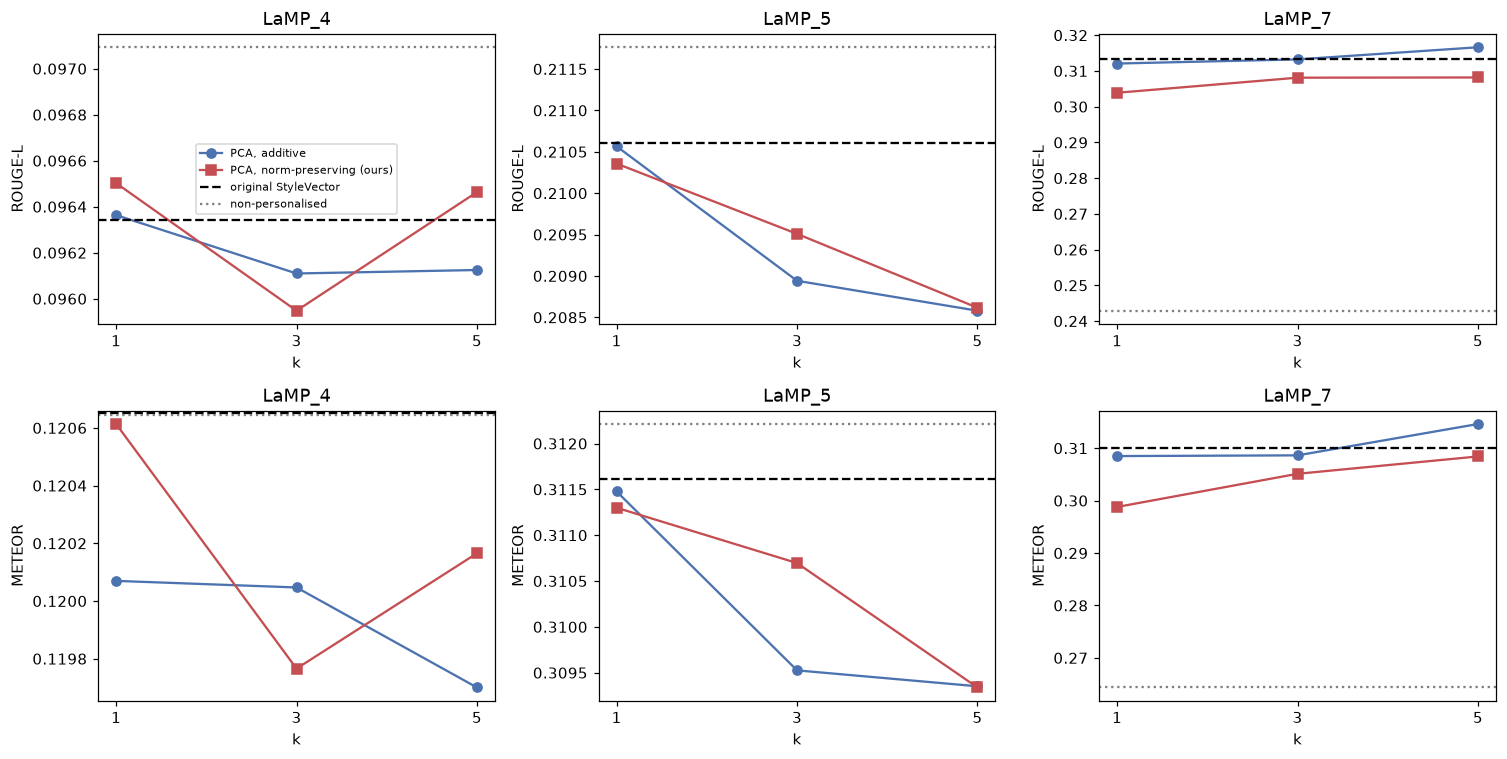

In [43]:
# Cell 6.4 — Effect of k (number of PCA components), with and without norm preservation
fig, axes = plt.subplots(2, len(TASKS), figsize=(4.6 * len(TASKS), 7), squeeze=False)
for j, task in enumerate(TASKS):
    sub = long_main[long_main["task"] == task]
    m = sub.groupby("config")[["rougeL", "meteor"]].mean()
    for i, (metric, name) in enumerate([("rougeL", "ROUGE-L"), ("meteor", "METEOR")]):
        ax = axes[i, j]
        ax.plot(K_LIST, [m.loc[f"pca{k}_add", metric] for k in K_LIST], "o-", label="PCA, additive", color="#4c72b0")
        ax.plot(K_LIST, [m.loc[f"pca{k}_np", metric] for k in K_LIST], "s-", label="PCA, norm-preserving (ours)", color="#c44e52")
        ax.axhline(m.loc[BASE_SV, metric], ls="--", color="k", label="original StyleVector")
        ax.axhline(m.loc["base", metric], ls=":", color="gray", label="non-personalised")
        ax.set_xticks(K_LIST); ax.set_xlabel("k"); ax.set_ylabel(name); ax.set_title(f"{task}")
        if i == 0 and j == 0: ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(CHECKPOINT_DIR / "k_sweep.png", dpi=150); plt.show()

### 6.5 Is any difference real? Paired bootstrap confidence intervals
Every method is evaluated on the *same* users, so we bootstrap the per-user **paired** score difference.
A gain is only reported when the 95% CI excludes zero.

In [44]:
# Cell 6.5 — Paired bootstrap of per-user differences
def paired_bootstrap(diff, n_boot=5000, seed=0):
    diff = np.asarray(diff, dtype=float)
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(diff), (n_boot, len(diff)))
    means = diff[idx].mean(1)
    lo, hi = np.percentile(means, [2.5, 97.5])
    return diff.mean(), lo, hi

def compare(long, a, b, tasks=TASKS):
    """a minus b, per task and metric."""
    rows = []
    for task in tasks:
        sub = long[long["task"] == task]
        for metric, name in [("rougeL", "ROUGE-L"), ("meteor", "METEOR")]:
            w = sub.pivot(index="user_id", columns="config", values=metric)
            if a not in w or b not in w: continue
            d = (w[a] - w[b]).dropna().values
            if len(d) < 2: continue
            mean, lo, hi = paired_bootstrap(d)
            rows.append({"Task": task, "Metric": name, "A": a, "B": b, "mean diff (A-B)": mean,
                         "95% CI lo": lo, "95% CI hi": hi, "A wins %": 100 * (d > 0).mean(),
                         "ties %": 100 * (d == 0).mean(), "n": len(d),
                         "verdict": "A better" if lo > 0 else ("A worse" if hi < 0 else "inconclusive")})
    return pd.DataFrame(rows)

comparisons = pd.concat([
    compare(long_main, FULL_NAME, BASE_SV),                        # our full method vs original StyleVector
    compare(long_main, FULL_NAME, cname("pca", K_FULL, False)),    # effect of norm preservation (multi-comp)
    compare(long_main, cname("pca", K_FULL, False), BASE_SV),      # effect of multi-component only (additive)
    compare(long_main, cname("mean", 1, True), BASE_SV),           # effect of norm preservation only (single)
    compare(long_main, BASE_SV, "base"),                           # original StyleVector vs no personalisation
    compare(long_main, FULL_NAME, "base"),                         # our full method vs no personalisation
], ignore_index=True)
comparisons.round(4)

,Task,Metric,A,B,mean diff (A-B),95% CI lo,95% CI hi,A wins %,ties %,n,verdict
0,LaMP_4,ROUGE-L,pca3_np,single_add,-0.0004,-0.0015,0.0004,1.3333,97.0000,300,inconclusive
1,LaMP_4,METEOR,pca3_np,single_add,-0.0009,-0.0023,0.0002,1.3333,96.6667,300,inconclusive
2,LaMP_5,ROUGE-L,pca3_np,single_add,-0.0011,-0.0038,0.0006,1.6667,96.0000,300,inconclusive
3,LaMP_5,METEOR,pca3_np,single_add,-0.0009,-0.0037,0.0012,2.0000,96.3333,300,inconclusive
4,LaMP_7,ROUGE-L,pca3_np,single_add,-0.0052,-0.0161,0.0058,32.5503,30.5369,298,inconclusive
5,LaMP_7,METEOR,pca3_np,single_add,-0.0048,-0.0159,0.0065,34.5638,26.1745,298,inconclusive
6,LaMP_4,ROUGE-L,pca3_np,pca3_add,-0.0002,-0.0005,0.0001,0.6667,98.6667,300,inconclusive
7,LaMP_4,METEOR,pca3_np,pca3_add,-0.0003,-0.0009,0.0000,0.6667,98.6667,300,inconclusive
8,LaMP_5,ROUGE-L,pca3_np,pca3_add,0.0006,-0.0000,0.0015,1.0000,98.6667,300,inconclusive
9,LaMP_5,METEOR,pca3_np,pca3_add,0.0012,0.0000,0.0028,1.3333,98.6667,300,A better


In [45]:
# Cell 6.6 — Plain-language verdict: does our full method beat the reproduced StyleVector?
v = compare(long_main, FULL_NAME, BASE_SV)
print(f"Our full method ({FULL_NAME}) vs original StyleVector ({BASE_SV}), paired bootstrap 95% CI\n")
for task in TASKS:
    for metric in ["ROUGE-L", "METEOR"]:
        r = v[(v["Task"] == task) & (v["Metric"] == metric)]
        if len(r):
            r = r.iloc[0]
            print(f"{task:7s} {metric:8s}: diff = {r['mean diff (A-B)']:+.4f}  "
                  f"CI [{r['95% CI lo']:+.4f}, {r['95% CI hi']:+.4f}]  -> {r['verdict']}")
n_better = sum((v[v['Task']==t]['verdict'] == 'A better').any() for t in TASKS)
print(f"\nTasks with a statistically clear gain on at least one metric: {n_better}/{len(TASKS)} "
      f"(proposal target: >= 2 of 3)")

Our full method (pca3_np) vs original StyleVector (single_add), paired bootstrap 95% CI

LaMP_4  ROUGE-L : diff = -0.0004  CI [-0.0015, +0.0004]  -> inconclusive
LaMP_4  METEOR  : diff = -0.0009  CI [-0.0023, +0.0002]  -> inconclusive
LaMP_5  ROUGE-L : diff = -0.0011  CI [-0.0038, +0.0006]  -> inconclusive
LaMP_5  METEOR  : diff = -0.0009  CI [-0.0037, +0.0012]  -> inconclusive
LaMP_7  ROUGE-L : diff = -0.0052  CI [-0.0161, +0.0058]  -> inconclusive
LaMP_7  METEOR  : diff = -0.0048  CI [-0.0159, +0.0065]  -> inconclusive

Tasks with a statistically clear gain on at least one metric: 0/3 (proposal target: >= 2 of 3)


### 6.7 Steering-strength sweep — does norm preservation tolerate larger $\alpha$?
The proposal's second hypothesis: additive steering collapses at large $\alpha$ (paper Fig. 3), norm-preserving steering should degrade more gracefully.
The x-axis is a multiplier on the task's `alpha`. We also track a simple **degenerate-output rate** (empty output, or heavily repeated tokens).

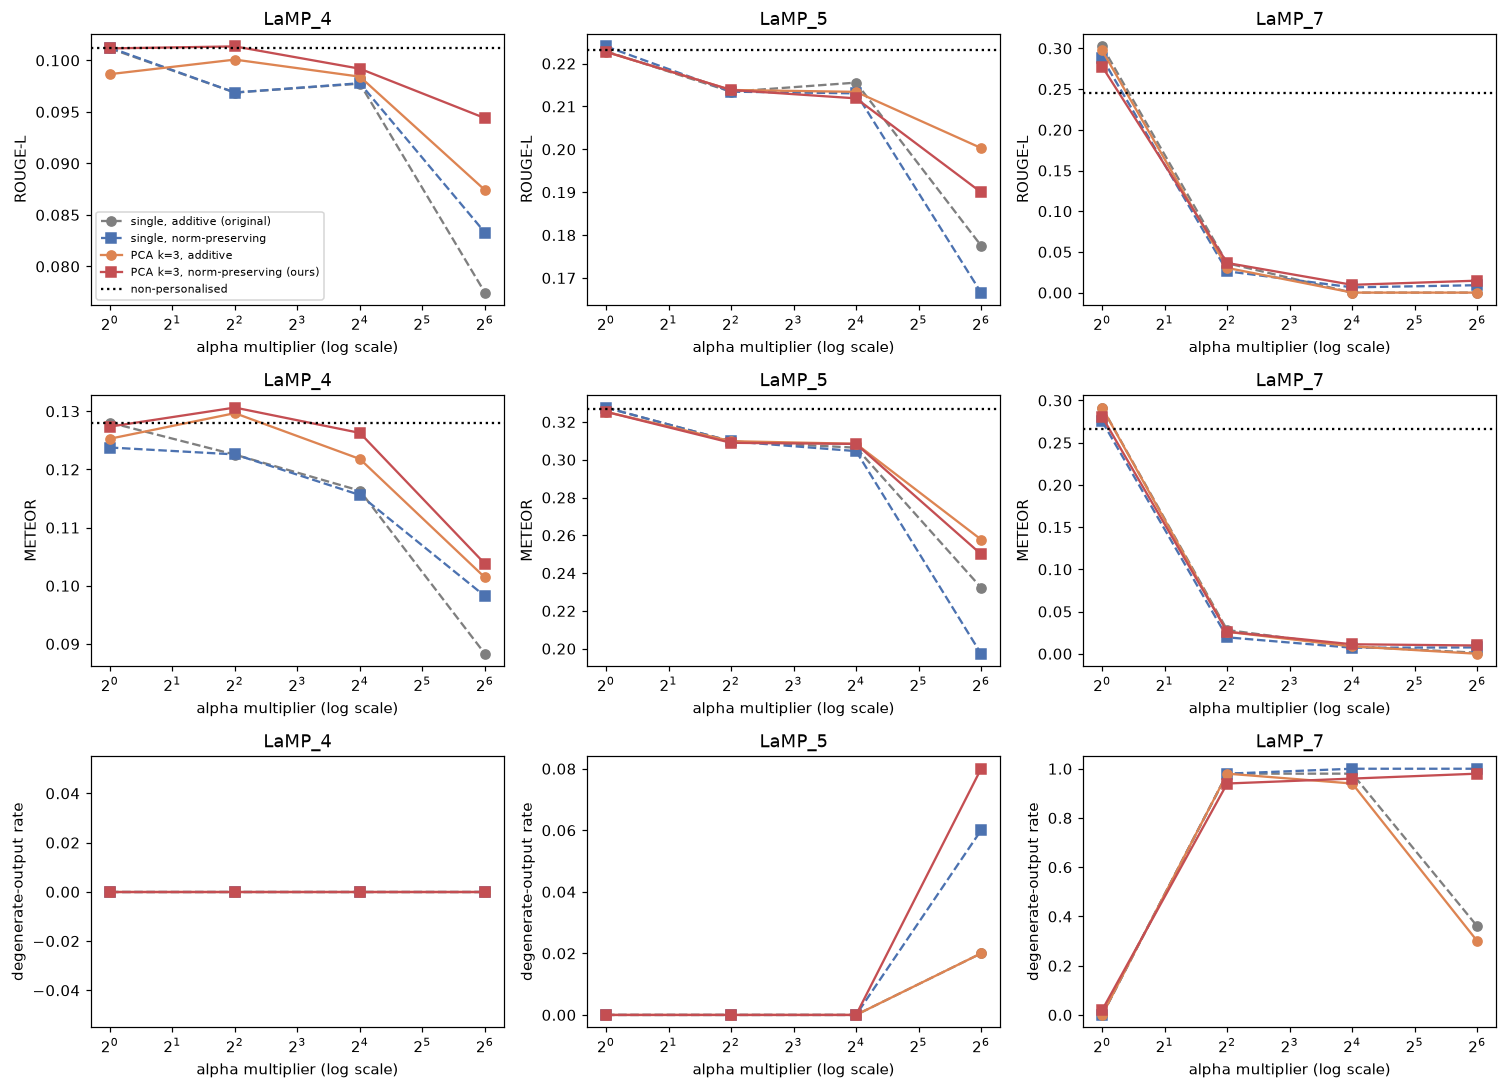

rougeL  meteor  degenerate  words
task   method norm  mult                                   
LaMP_4 mean   False 1.0   0.1012  0.1281        0.00  22.82
                    4.0   0.0969  0.1226        0.00  22.84
                    16.0  0.0977  0.1164        0.00  22.94
                    64.0  0.0775  0.0883        0.00  18.30
              True  1.0   0.1012  0.1238        0.00  22.78
                    4.0   0.0969  0.1226        0.00  22.92
                    16.0  0.0978  0.1156        0.00  22.90
                    64.0  0.0833  0.0982        0.00  19.52
       pca    False 1.0   0.0987  0.1253        0.00  22.84
                    4.0   0.1001  0.1297        0.00  22.90
                    16.0  0.0984  0.1218        0.00  23.06
                    64.0  0.0874  0.1014        0.00  20.10
              True  1.0   0.1012  0.1274        0.00  22.82
                    4.0   0.1014  0.1306        0.00  22.92
                    16.0  0.0992  0.1263        0.00  22.88
                    64.0  0.0944  0.1038        0.00  21.12
LaMP_5 mean   False 1.0   0.2229  0.3276        0.00  24.40
                    4.0   0.2134  0.3097        0.00  24.42
                    16.0  0.2155  0.3064        0.00  24.16
                    64.0  0.1775  0.2323        0.02  20.94
              True  1.0   0.2240  0.3276        0.00  24.38
                    4.0   0.2134  0.3097        0.00  24.42
                    16.0  0.2130  0.3046        0.00  24.18
                    64.0  0.1666  0.1973        0.06  20.48
       pca    False 1.0   0.2227  0.3254        0.00  24.36
                    4.0   0.2138  0.3098        0.00  24.34
                    16.0  0.2134  0.3084        0.00  24.02
                    64.0  0.2003  0.2578        0.02  22.14
              True  1.0   0.2227  0.3254        0.00  24.36
                    4.0   0.2138  0.3090        0.00  24.34
                    16.0  0.2119  0.3084        0.00  24.08
                    64.0  0.1900  0.2500        0.08  22.02
LaMP_7 mean   False 1.0   0.3025  0.2915        0.00  19.10
                    4.0   0.0361  0.0281        0.98  25.94
                    16.0  0.0000  0.0086        0.98  38.58
                    64.0  0.0000  0.0012        0.36  12.70
              True  1.0   0.2880  0.2751        0.00  18.58
                    4.0   0.0262  0.0194        0.98  25.32
                    16.0  0.0064  0.0071        1.00  11.06
                    64.0  0.0091  0.0075        1.00   7.34
       pca    False 1.0   0.2974  0.2912        0.00  18.90
                    4.0   0.0303  0.0260        0.98  22.38
                    16.0  0.0000  0.0088        0.94  35.80
                    64.0  0.0000  0.0000        0.30   9.10
              True  1.0   0.2777  0.2806        0.02  18.62
                    4.0   0.0364  0.0261        0.94  25.36
                    16.0  0.0095  0.0112        0.96  14.98
                    64.0  0.0147  0.0098        0.98  11.50

In [46]:
# Cell 6.7 — Strength sweep: quality and degeneration vs. multiplier
long_str = load_long("strength", TASKS)

def is_degenerate(text):
    toks = re.findall(r"\w+|[^\w\s]", text.lower())
    if len(toks) == 0: return True
    return len(toks) >= 8 and len(set(toks)) / len(toks) < 0.4

long_str["degenerate"] = long_str["pred"].map(is_degenerate)
long_str["n_words"] = long_str["pred"].str.split().str.len()

label = {("mean", False): "single, additive (original)", ("mean", True): "single, norm-preserving",
         ("pca", False): f"PCA k={K_FULL}, additive", ("pca", True): f"PCA k={K_FULL}, norm-preserving (ours)"}
style = {("mean", False): ("#7f7f7f", "o--"), ("mean", True): ("#4c72b0", "s--"),
         ("pca", False): ("#dd8452", "o-"),  ("pca", True): ("#c44e52", "s-")}

fig, axes = plt.subplots(3, len(TASKS), figsize=(4.6 * len(TASKS), 10), squeeze=False)
for j, task in enumerate(TASKS):
    sub = long_str[long_str["task"] == task]
    base_r, base_m = sub[sub.method == "base"][["rougeL", "meteor"]].mean()
    for i, (col, name) in enumerate([("rougeL", "ROUGE-L"), ("meteor", "METEOR"), ("degenerate", "degenerate-output rate")]):
        ax = axes[i, j]
        for (meth, nrm), lab in label.items():
            s = sub[(sub.method == meth) & (sub.norm == nrm)].groupby("mult")[col].mean()
            ax.plot(s.index, s.values, style[(meth, nrm)][1], color=style[(meth, nrm)][0], label=lab)
        if col != "degenerate":
            ax.axhline(base_r if col == "rougeL" else base_m, ls=":", color="k", label="non-personalised")
        ax.set_xscale("log", base=2); ax.set_xlabel("alpha multiplier (log scale)"); ax.set_ylabel(name)
        ax.set_title(task)
        if i == 0 and j == 0: ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(CHECKPOINT_DIR / "strength_sweep.png", dpi=150); plt.show()

tbl = (long_str[long_str.method != "base"]
       .groupby(["task", "method", "norm", "mult"])
       .agg(rougeL=("rougeL", "mean"), meteor=("meteor", "mean"),
            degenerate=("degenerate", "mean"), words=("n_words", "mean")).round(4))
tbl

In [47]:
# Cell 6.8 — Activation-magnitude diagnostic: how large is ||h+p|| / ||h|| under additive steering?
# (Norm-preserving steering keeps this ratio at exactly 1.0 by construction.)
N_DIAG = 10
diag_rows = []
for task in TASKS:
    cfg = BEST_CONFIG[task]
    layer = cfg["layer"]
    for uid in list(eval_users[task])[:N_DIAG]:
        path = delta_cache_path(task, uid)
        if not path.exists():
            continue
        D = torch.load(path, map_location="cpu")["deltas"][layer].float()
        ids = build_input_ids(tokenizer, TASK_PROMPTS[task](eval_users[task][uid]["query_input"]), model.device)
        h = last_prompt_activation(ids, layer)
        for m in MULTS:
            for meth, k in [("mean", 1), ("pca", K_FULL)]:
                p = build_perturbation(D, meth, k, cfg["alpha"] * m)
                diag_rows.append({"task": task, "mult": m, "method": meth,
                                  "||h||": h.norm().item(), "||p||": p.norm().item(),
                                  "||h+p||/||h||": ((h + p).norm() / h.norm()).item()})
diag = pd.DataFrame(diag_rows)
print("Mean over users of the additive-steering magnitude ratio at the last prompt token:")
diag.groupby(["task", "method", "mult"])[["||h||", "||p||", "||h+p||/||h||"]].mean().round(3)

/tmp/ipykernel_65560/2585600343.py:12: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  D = torch.load(path, map_location="cpu")["deltas"][layer].float()


Mean over users of the additive-steering magnitude ratio at the last prompt token:


||h||    ||p||  ||h+p||/||h||
task   method mult                                
LaMP_4 mean   1     30.472    0.303          0.999
              4     30.472    1.210          0.996
              16    30.472    4.840          0.993
              64    30.472   19.361          1.116
       pca    1     30.472    0.303          1.000
              4     30.472    1.210          0.999
              16    30.472    4.840          1.007
              64    30.472   19.361          1.166
LaMP_5 mean   1     29.322    0.321          0.999
              4     29.322    1.283          0.998
              16    29.322    5.133          1.005
              64    29.322   20.532          1.188
       pca    1     29.322    0.321          1.000
              4     29.322    1.283          1.000
              16    29.322    5.133          1.012
              64    29.322   20.532          1.212
LaMP_7 mean   1     29.299   13.902          1.013
              4     29.299   55.607          1.951
              16    29.299  222.429          7.447
              64    29.299  889.716         30.175
       pca    1     29.299   13.902          1.021
              4     29.299   55.607          1.967
              16    29.299  222.429          7.464
              64    29.299  889.716         30.192

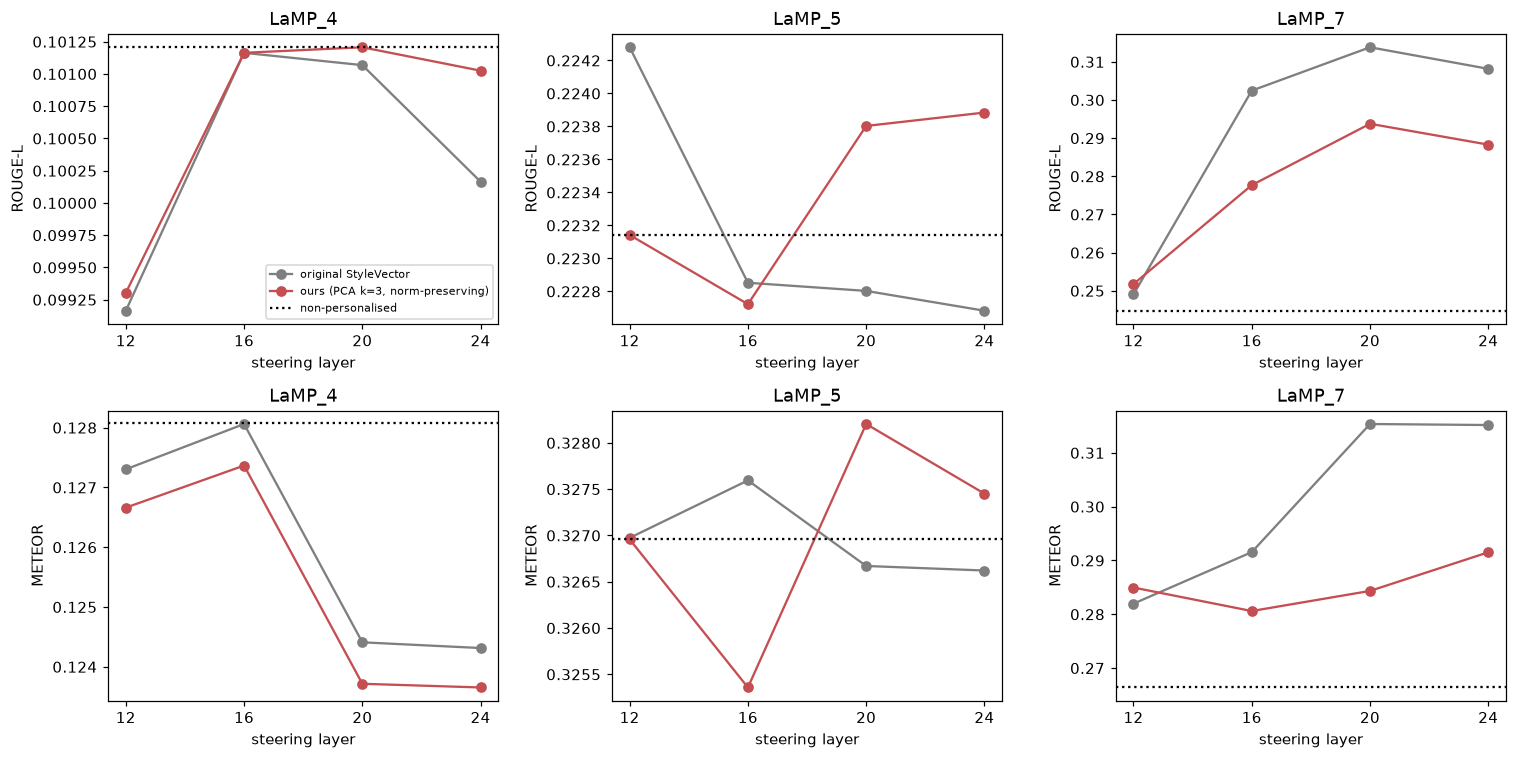

rougeL  meteor
task   layer config                        
LaMP_4 12.0  pca3_np@L12     0.0993  0.1267
             single_add@L12  0.0992  0.1273
       16.0  pca3_np@L16     0.1012  0.1274
             single_add@L16  0.1012  0.1281
       20.0  pca3_np@L20     0.1012  0.1237
             single_add@L20  0.1011  0.1244
       24.0  pca3_np@L24     0.1010  0.1237
             single_add@L24  0.1002  0.1243
LaMP_5 12.0  pca3_np@L12     0.2231  0.3270
             single_add@L12  0.2243  0.3270
       16.0  pca3_np@L16     0.2227  0.3254
             single_add@L16  0.2229  0.3276
       20.0  pca3_np@L20     0.2238  0.3282
             single_add@L20  0.2228  0.3267
       24.0  pca3_np@L24     0.2239  0.3275
             single_add@L24  0.2227  0.3266
LaMP_7 12.0  pca3_np@L12     0.2518  0.2850
             single_add@L12  0.2491  0.2820
       16.0  pca3_np@L16     0.2777  0.2806
             single_add@L16  0.3025  0.2915
       20.0  pca3_np@L20     0.2938  0.2843
             single_add@L20  0.3138  0.3154
       24.0  pca3_np@L24     0.2883  0.2915
             single_add@L24  0.3082  0.3152

In [48]:
# Cell 6.9 — Layer sweep: original StyleVector vs. our full method at each steering layer
long_lay = load_long("layer", TASKS)
fig, axes = plt.subplots(2, len(TASKS), figsize=(4.6 * len(TASKS), 7), squeeze=False)
for j, task in enumerate(TASKS):
    sub = long_lay[long_lay["task"] == task]
    for i, (col, name) in enumerate([("rougeL", "ROUGE-L"), ("meteor", "METEOR")]):
        ax = axes[i, j]
        for (meth, nrm), lab, colr in [(("mean", False), "original StyleVector", "#7f7f7f"),
                                       (("pca", True), f"ours (PCA k={K_FULL}, norm-preserving)", "#c44e52")]:
            s = sub[(sub.method == meth) & (sub.norm == nrm)].groupby("layer")[col].mean()
            ax.plot(s.index, s.values, "o-", color=colr, label=lab)
        ax.axhline(sub[sub.method == "base"][col].mean(), ls=":", color="k", label="non-personalised")
        ax.set_xticks(LAYER_SWEEP); ax.set_xlabel("steering layer"); ax.set_ylabel(name); ax.set_title(task)
        if i == 0 and j == 0: ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(CHECKPOINT_DIR / "layer_sweep.png", dpi=150); plt.show()

long_lay[long_lay.method != "base"].groupby(["task", "layer", "config"])[["rougeL", "meteor"]].mean().round(4)

### 6.10 What do the extra components capture?
Uncentered energy share of each component, and how aligned each component is with the original mean-difference direction.
If $v_1$ is almost identical to the mean direction and $v_2,v_3,\dots$ carry non-trivial energy, the extra components add genuinely new directions.

In [49]:
# Cell 6.10 — Component diagnostics from the cached deltas (no model needed)
KMAX = max(K_LIST)
diag_comp, tsne_data = [], {}
for task in TASKS:
    layer = BEST_CONFIG[task]["layer"]
    comps = []
    for uid in eval_users[task]:
        path = delta_cache_path(task, uid)
        if not path.exists():
            continue
        D = torch.load(path, map_location="cpu")["deltas"][layer].float()
        if D.shape[0] < KMAX:                       # need full rank KMAX for a clean average
            continue
        _, S, _ = torch.linalg.svd(D, full_matrices=False)
        V, lam = style_components(D, KMAX)
        share = (S ** 2 / (S ** 2).sum())[:KMAX]
        cos = torch.nn.functional.cosine_similarity(V, D.mean(0, keepdim=True), dim=1)
        for j in range(KMAX):
            diag_comp.append({"task": task, "component": j + 1, "energy share": share[j].item(),
                              "cos(v_j, mean-diff)": cos[j].item()})
        comps.append(V[:K_FULL].numpy())
    tsne_data[task] = np.stack(comps) if comps else None

diag_comp = pd.DataFrame(diag_comp)
summary_comp = diag_comp.groupby(["task", "component"]).mean().round(3)
display(summary_comp)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(axes, ["energy share", "cos(v_j, mean-diff)"]):
    piv = diag_comp.groupby(["component", "task"])[col].mean().unstack()
    piv.plot(kind="bar", ax=ax, rot=0); ax.set_title(col); ax.set_xlabel("PCA component j")
plt.tight_layout(); plt.savefig(CHECKPOINT_DIR / "component_diagnostics.png", dpi=150); plt.show()

/tmp/ipykernel_65560/2136766790.py:11: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  D = torch.load(path, map_location="cpu")["deltas"][layer].float()


EOFError: Ran out of input

In [ ]:
# Cell 6.11 — t-SNE of the extracted style directions (proposal: qualitative analysis)
from sklearn.manifold import TSNE
fig, axes = plt.subplots(1, len(TASKS), figsize=(5 * len(TASKS), 4.5), squeeze=False)
for ax, task in zip(axes[0], TASKS):
    arr = tsne_data.get(task)
    if arr is None or len(arr) < 10:
        ax.set_title(f"{task}: not enough cached users"); continue
    n, k, d = arr.shape
    X = arr.reshape(n * k, d)
    lab = np.tile(np.arange(1, k + 1), n)
    emb = TSNE(n_components=2, init="pca", perplexity=min(30, len(X) // 4),
               random_state=RNG_SEED).fit_transform(X)
    for j in range(1, k + 1):
        ax.scatter(*emb[lab == j].T, s=8, alpha=0.6, label=f"component {j}")
    ax.set_title(f"{task}: top-{k} style directions per user"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(CHECKPOINT_DIR / "tsne_components.png", dpi=150); plt.show()

In [ ]:
# Cell 6.12 — Qualitative case study (paper Fig. 5 style): gold vs. base vs. original StyleVector vs. ours
N_CASES = 5
for task in TASKS:
    print(f"\n{'='*25} {task} — sample cases (first users where methods differ) {'='*25}")
    w = long_main[long_main.task == task].pivot(index="user_id", columns="config", values="pred")
    gold = long_main[long_main.task == task].drop_duplicates("user_id").set_index("user_id")["gold"]
    differing = w[w[FULL_NAME] != w[BASE_SV]].head(N_CASES)
    for uid, row in differing.iterrows():
        print(f"\n[user {uid}]")
        print(f"  gold          : {gold[uid][:90]!r}")
        print(f"  base          : {row['base'][:90]!r}")
        print(f"  StyleVector   : {row[BASE_SV][:90]!r}")
        print(f"  ours ({FULL_NAME}): {row[FULL_NAME][:90]!r}")

### 6.13 Sanity check against the paper's Table 2 (raw, unadjusted)
Different model size/precision, generic-response model ($M_g$ = LLaMA-2 here vs. GPT-3.5 in the paper) and a small user sample mean absolute numbers will differ; this is only a check on the *direction* of the effect.

In [ ]:
# Cell 6.13 — Raw comparison with the paper's Table 2 (LaMP rows). No adjustments applied.
PAPER_NUMBERS = {
    "LaMP_4": {"rougeL_base": 0.0398, "meteor_base": 0.0790, "rougeL_sv": 0.0411, "meteor_sv": 0.0809},
    "LaMP_5": {"rougeL_base": 0.1086, "meteor_base": 0.2337, "rougeL_sv": 0.1366, "meteor_sv": 0.2575},
    "LaMP_7": {"rougeL_base": 0.2506, "meteor_base": 0.2588, "rougeL_sv": 0.2827, "meteor_sv": 0.3042},
}
rows = []
for task in TASKS:
    m = long_main[long_main.task == task].groupby("config")[["rougeL", "meteor"]].mean()
    if BASE_SV not in m.index: continue
    p = PAPER_NUMBERS[task]
    for metric, name, kb, ks in [("rougeL", "ROUGE-L", "rougeL_base", "rougeL_sv"), ("meteor", "METEOR", "meteor_base", "meteor_sv")]:
        rows.append({"Task": task, "Metric": name,
                     "Paper base": p[kb], "Paper StyleVector": p[ks],
                     "Paper Δ%": 100 * (p[ks] - p[kb]) / p[kb],
                     "Ours base": m.loc["base", metric], "Ours StyleVector": m.loc[BASE_SV, metric],
                     "Ours Δ%": 100 * (m.loc[BASE_SV, metric] - m.loc["base", metric]) / m.loc["base", metric],
                     f"Ours {FULL_NAME}": m.loc[FULL_NAME, metric],
                     f"{FULL_NAME} Δ% vs base": 100 * (m.loc[FULL_NAME, metric] - m.loc["base", metric]) / m.loc["base", metric]})
paper_table = pd.DataFrame(rows)
paper_table.round(4)

## Part 7 — Save Everything

In [ ]:
# Cell 7.1 — Export all tables, per-user results and figures
long_main.to_csv(CHECKPOINT_DIR / "main_long.csv", index=False)
long_str.to_csv(CHECKPOINT_DIR / "strength_long.csv", index=False)
long_lay.to_csv(CHECKPOINT_DIR / "layer_long.csv", index=False)
summary_main.to_csv(CHECKPOINT_DIR / "summary_main.csv", index=False)
comparisons.to_csv(CHECKPOINT_DIR / "paired_comparisons.csv", index=False)
paper_table.to_csv(CHECKPOINT_DIR / "paper_sanity_check.csv", index=False)
summary_comp.to_csv(CHECKPOINT_DIR / "component_diagnostics.csv")
for metric, name in [("rougeL", "rougeL"), ("meteor", "meteor")]:
    ablation_2x2(long_main, metric).to_csv(CHECKPOINT_DIR / f"ablation_2x2_{name}.csv")
print("Saved to:", CHECKPOINT_DIR.resolve())
for p in sorted(CHECKPOINT_DIR.glob("*.csv")) + sorted(CHECKPOINT_DIR.glob("*.png")):
    print(" -", p.name)

In [51]:
del model
torch.cuda.empty_cache()

NameError: name 'model' is not defined